# PPMI: Clinical and protein predictors of motor progression score (UPDRS III)

Predict `slope_updrs3_off` (UPDRS III points/year) using clinical variables, proteins, or both. Compare these ridge models with a training-mean baseline. Units are points per year.

You will need to update the data path if you want to run the code yourself. The data is not included since the PPMI data is not public.

## 1. Imports

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV
plt.style.use("default")
# Plot appearance
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

## 2. Load data

In [51]:
DATA_PATH = Path("./data/processed/ppmi_csf_corrected.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df["EVENT_ID"].value_counts(dropna=False))
df.head()


,PATNO,EVENT_ID,COHORT,subgroup,YEAR,age_at_visit,SEX,duration_yrs,PDTRTMNT,LEDD,...,harmonized_olink_csf_ZPR1_NPX,harmonized_olink_csf_ZRANB1_NPX,harmonized_olink_csf_ZRANB3_NPX,harmonized_olink_csf_ZRSR2_NPX,harmonized_olink_csf_ZSCAN21_NPX,harmonized_olink_csf_ZSCAN31_NPX,harmonized_olink_csf_ZSWIM3_NPX,harmonized_olink_csf_ZSWIM8_NPX,harmonized_olink_csf_ZUP1_NPX,harmonized_olink_csf_ZWILCH_NPX
0,100001,BL,1,Sporadic PD,0,67.386301,1,1.060274,0.0,0.0,...,0.773263,1.188246,0.990225,0.988592,0.819212,0.009896,0.723148,0.709345,-0.052981,0.145561
1,100001,V08,1,Sporadic PD,3,70.484932,1,1.060274,0.0,0.0,...,0.530185,-1.047136,0.474757,0.103241,0.146384,-0.110740,0.184543,0.476878,0.083233,2.742000
2,100002,BL,1,Sporadic PD,0,58.517808,1,0.216438,0.0,0.0,...,0.799676,-2.303332,0.505933,0.930263,-0.027122,0.059437,0.078359,0.381601,0.373377,0.063239
3,100002,V08,1,Sporadic PD,3,61.561644,1,0.216438,1.0,450.0,...,0.598710,0.693462,-0.106457,0.837877,0.007749,0.009507,0.295731,0.656655,-0.343350,-3.944628
4,100005,BL,1,Sporadic PD,0,52.791781,1,1.556164,0.0,0.0,...,-0.162698,-0.833370,-0.452372,-2.291568,-0.846866,-0.152775,0.097061,-0.058815,-0.720301,-7.258085


## 3. Configuration

In [52]:
TARGET = "slope_updrs3_off"
BATCH = "harmonized_olink_csf_src"
BASELINE_EVENT = "BL"  # Confirm against the visit counts above.
SEED = 42
clinical_numeric = [
    "age_at_visit", "duration_yrs", "LEDD", "updrs1_score",
    "updrs2_score", "updrs3_score", "updrs4_score",
]
clinical_categorical = ["SEX", "PDTRTMNT"]
proteins = sorted(c for c in df.columns
    if c.startswith("harmonized_olink_csf_") and c.endswith("_NPX"))
print("Protein columns:", len(proteins))

Protein columns: 5416


## 4. Select the same baseline patients for every model

In [53]:
# Keep Parkinson's disease patients and recover their slope from any visit.
data = df.loc[pd.to_numeric(df["COHORT"], errors="coerce").eq(1)
              & df["PATNO"].notna()].copy()
data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
patient_targets = data.groupby("PATNO")[TARGET].first()
baseline = data.loc[data["EVENT_ID"].astype(str).str.strip().eq(BASELINE_EVENT)].copy()
baseline[TARGET] = baseline["PATNO"].map(patient_targets)

# Convert measurements to numbers; treat invalid values as missing.
for column in clinical_numeric + proteins:
    baseline[column] = pd.to_numeric(baseline[column], errors="coerce")
baseline[clinical_numeric + proteins] = baseline[clinical_numeric + proteins].replace(
    [np.inf, -np.inf], np.nan)

# Require an outcome and at least one protein measurement for a fair comparison.
eligible = np.isfinite(baseline[TARGET]) & baseline[proteins].notna().any(axis=1)
model_df = baseline.loc[eligible].reset_index(drop=True)
y = model_df[TARGET].to_numpy(dtype=float)

# Include batch when available and encode categories as text.
batch_columns = [BATCH] if BATCH in model_df.columns else []
categorical_columns = clinical_categorical + batch_columns
for column in categorical_columns:
    model_df[column] = model_df[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
print(f"Patients used in all models: {len(model_df)}")

Patients used in all models: 819


## 5. Review missingness

In [54]:
missingness = model_df[clinical_numeric + proteins].isna().mean().sort_values(ascending=False)
display(missingness.rename("Missing fraction").to_frame().head(25))


,Missing fraction
updrs4_score,0.886447
harmonized_olink_csf_CLTB_NPX,0.805861
harmonized_olink_csf_APOE_NPX,0.727717
harmonized_olink_csf_REPS1_NPX,0.247863
harmonized_olink_csf_VIL1_NPX,0.244200
harmonized_olink_csf_RNF4_NPX,0.240537
harmonized_olink_csf_RIBC1_NPX,0.236874
harmonized_olink_csf_L3MBTL2_NPX,0.235653
harmonized_olink_csf_MFAP3_NPX,0.233211
harmonized_olink_csf_MMUT_NPX,0.230769


## 6. Split patients (training/test)

In [55]:
train_idx, test_idx = train_test_split(
    np.arange(len(model_df)), test_size=0.20, random_state=SEED)
train = model_df.iloc[train_idx]
test = model_df.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f"Training patients: {len(train)}; test patients: {len(test)}")

Training patients: 655; test patients: 164


## 7. Define the simple ridge model

In [56]:
ALPHA = 10.0  # Fixed penalty for the initial train/test comparison.

def build_ridge(numeric_columns, categorical_columns, alpha=ALPHA):
    # Learn medians and scaling from training patients only.
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ("numeric", numeric, numeric_columns),
        ("categorical", categorical, categorical_columns),
    ])
    return Pipeline([("preprocessing", preprocess),
                     ("model", Ridge(alpha=alpha, solver="lsqr"))])

def calculate_metrics(actual, predicted):
    # Lower RMSE/MAE is better; higher R² is better.
    return {
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }

feature_sets = {"Clinical": clinical_numeric,
                "Clinical + proteins": clinical_numeric + proteins}

## 8. Fit two models and predict held-out progression

In [57]:
models = {}
predictions = {"Mean baseline": np.full(len(y_test), y_train.mean())}
for name, columns in feature_sets.items():
    model = build_ridge(columns, categorical_columns)
    model.fit(train, y_train)
    models[name] = model
    predictions[name] = model.predict(test)
    print(f"Finished: {name}")

Finished: Clinical + proteins


## 9. Compare test performance

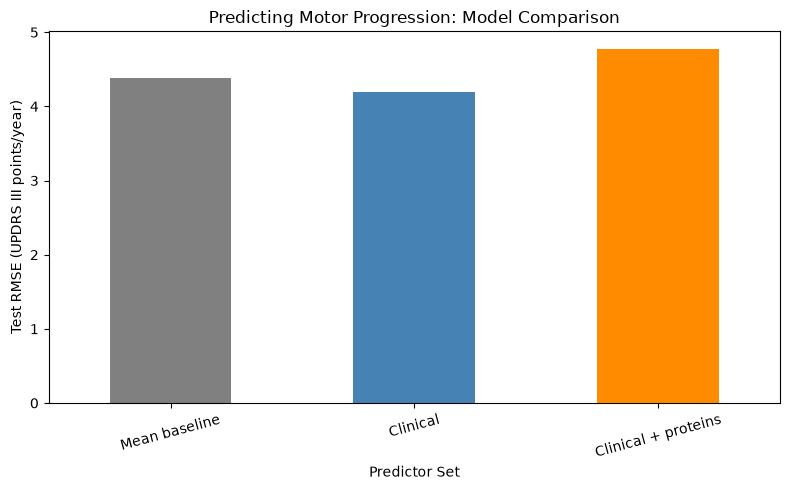

In [58]:
# Compare the initial models on the held-out 20% of patients.
performance = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_test, pred)}
    for name, pred in predictions.items()
]).set_index("Model")

display(performance.round(3))

gain = (
    performance.loc["Clinical", "RMSE"]
    - performance.loc["Clinical + proteins", "RMSE"]
)
print(f"RMSE improvement from adding proteins: {gain:.3f}")

# Create a new plot with a white background
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
ax.set_facecolor("white")

performance["RMSE"].plot.bar(
    ax=ax,
    color=["gray", "steelblue", "darkorange"],
    rot=15
)

ax.set_ylabel("Test RMSE (UPDRS III points/year)", color="black")
ax.set_xlabel("Predictor Set", color="black")
ax.set_title(
    "Predicting Motor Progression: Model Comparison",
    color="black"
)


plt.tight_layout()
plt.show()

Clinical-only performed best, with the lowest RMSE of approximately 4.2 points/year.
The mean baseline performed slightly worse, with an RMSE of approximately 4.4 points/year.
Adding proteins increased prediction error to approximately 4.8, showing no benefit on this test split.

## 10. Explore protein coefficients


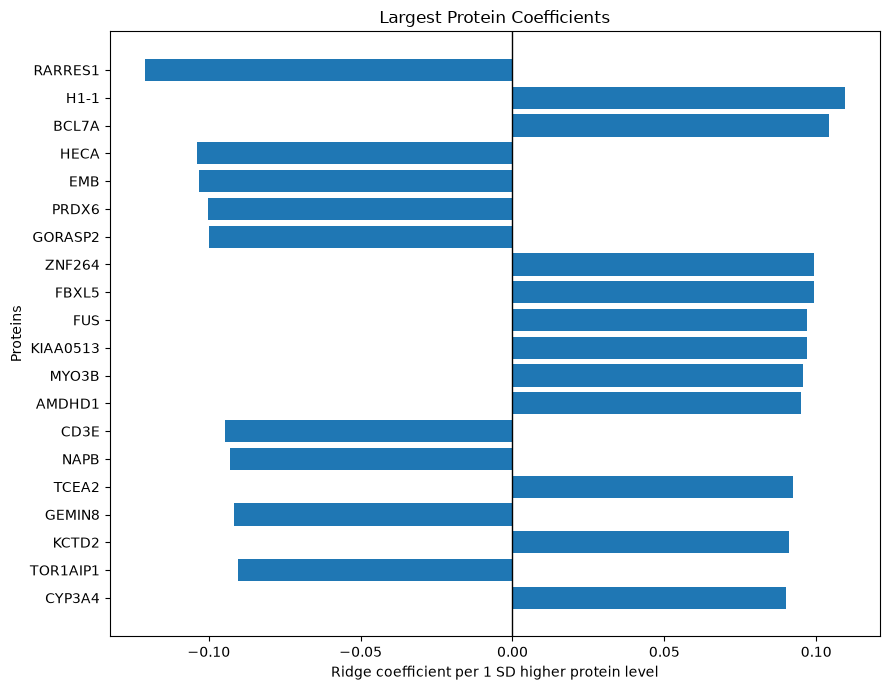

In [59]:
# Rank proteins by absolute coefficient. these are exploratory associations.
# High positive coefficient means protein associated with stronger slope.
# High negative coefficient means protein associated with lower slope.

combined = models["Clinical + proteins"]
coefficients = pd.DataFrame({
    "Feature": combined["preprocessing"].get_feature_names_out(),
    "Coefficient": combined["model"].coef_,
})
coefficients["Feature"] = coefficients["Feature"].str.replace(r"^[^_]+__", "", regex=True)
coefficients["Absolute coefficient"] = coefficients["Coefficient"].abs()
protein_coefficients = coefficients.loc[coefficients["Feature"].isin(proteins)].sort_values(
    "Absolute coefficient", ascending=False)
display(protein_coefficients.head(20))
top = protein_coefficients.head(20).iloc[::-1]
labels = top["Feature"].str.replace("harmonized_olink_csf_", "", regex=False).str.replace("_NPX", "", regex=False)
plt.figure(figsize=(9, 7))
plt.barh(labels, top["Coefficient"])
plt.axvline(0, color="black", linewidth=1)
plt.ylabel("Proteins")
plt.xlabel("Ridge coefficient per 1 SD higher protein level")
plt.title("Largest Protein Coefficients")
plt.tight_layout()
plt.show()

H1-1 and BCL7A have the largest positive coefficient, meaning higher levels are associated with faster predicted worsening.
RARRES1 has the largest negative coefficient, meaning higher levels are associated with a lower predicted progression rate.
These are exploratory model associations still.

## 11. Actual versus predicted progression

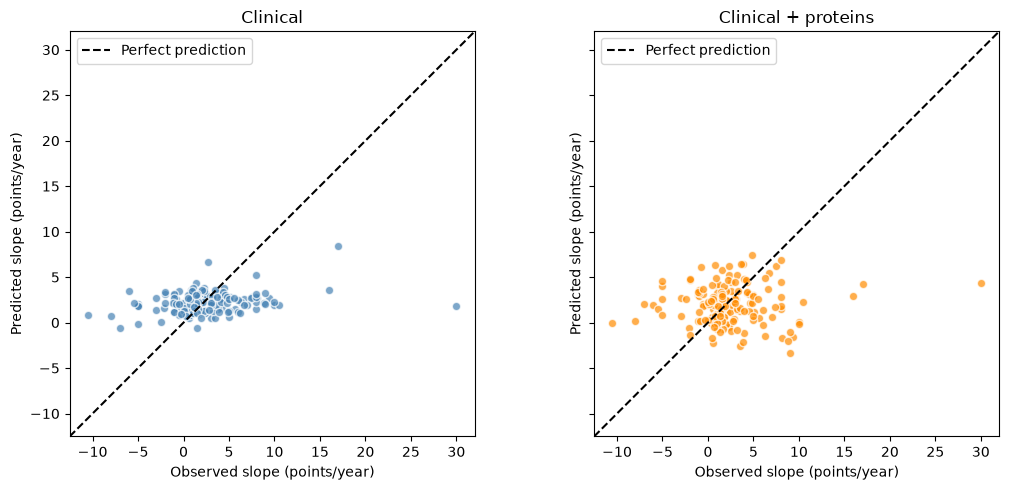

In [60]:
# Points on the diagonal would represent perfect predictions.
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
all_values = np.concatenate([y_test, predictions["Clinical"], predictions["Clinical + proteins"]])
low, high = all_values.min(), all_values.max()
pad = max((high - low) * 0.05, 0.1)
limits = [low - pad, high + pad]
for ax, name, color in zip(axes, ["Clinical", "Clinical + proteins"], ["steelblue", "darkorange"]):
    ax.scatter(y_test, predictions[name], color=color, alpha=0.7, edgecolors="white")
    ax.plot(limits, limits, "k--", label="Perfect prediction")
    ax.set(xlim=limits, ylim=limits, xlabel="Observed slope (points/year)",
           ylabel="Predicted slope (points/year)", title=name)
    ax.set_aspect("equal", adjustable="box")
    ax.legend()
plt.tight_layout()
plt.show()

Both models struggle to match actual progression rates, with many points far from the dashed perfect-prediction line.
Rapid worsening is underestimated, while patients with improving motor scores are often predicted to worsen.
Adding proteins produces more scattered predictions, without a clear improvement over clinical variables alone.

## 12. Add the proteins-only model

Use the same training and test patients, with batch adjustment when available.

In [61]:
# Reuse the same preprocessing function, excluding clinical variables.
protein_model = build_ridge(proteins, batch_columns)
protein_model.fit(train, y_train)
models["Proteins only"] = protein_model
predictions["Proteins only"] = protein_model.predict(test)
print("Finished: Proteins only")

Finished: Proteins only


## 13. Compare all four models

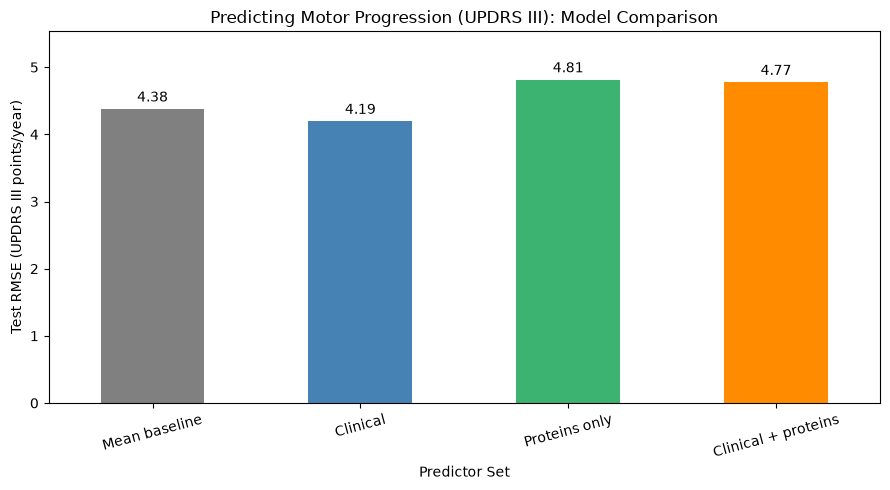

In [62]:
# Compare all four models on the same test patients.
performance = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_test, pred)}
    for name, pred in predictions.items()
]).set_index("Model")

order = [
    "Mean baseline",
    "Clinical",
    "Proteins only",
    "Clinical + proteins"
]
performance = performance.loc[order]

display(performance.round(3))


fig, ax = plt.subplots(figsize=(9, 5), facecolor="white")
ax.set_facecolor("white")

performance["RMSE"].plot.bar(
    ax=ax,
    color=["gray", "steelblue", "mediumseagreen", "darkorange"],
    rot=15
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.margins(y=0.15)

ax.set_ylabel("Test RMSE (UPDRS III points/year)")
ax.set_xlabel("Predictor Set")
ax.set_title("Predicting Motor Progression (UPDRS III): Model Comparison")

plt.tight_layout()
plt.show()

Clinical-only performed best, with the lowest prediction error (RMSE = 4.19), compared with 4.38 for the mean baseline.
Proteins-only performed worst (4.81), while combining clinical variables and proteins gave a similar error (4.77).
Adding proteins reduced prediction accuracy on this test split, rather than improving it.

## 14. Review progression rates

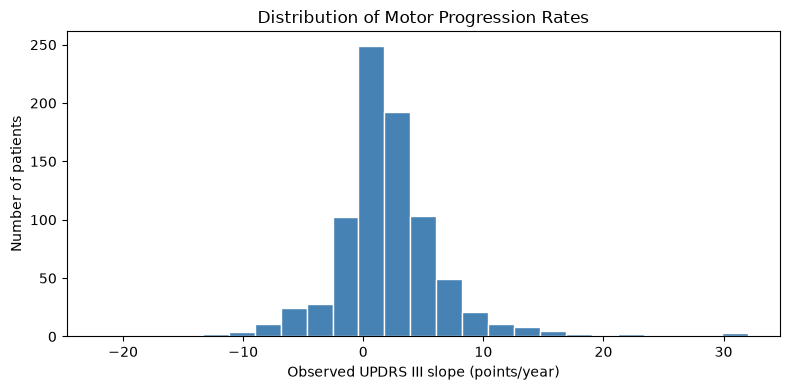

In [63]:
# Reuse the baseline sample already prepared above.
cv_data = model_df.copy()
y_cv = y.copy()
display(cv_data[TARGET].describe().to_frame("UPDRS III slope"))

# Most patients have modest slopes; the tails show more extreme values.
plt.figure(figsize=(8, 4))
plt.hist(y_cv, bins=25, color="steelblue", edgecolor="white")
plt.xlabel("Observed UPDRS III slope (points/year)")
plt.ylabel("Number of patients")
plt.title("Distribution of Motor Progression Rates")
plt.tight_layout()
plt.show()

Most patients had slopes near zero or slightly positive, indicating stable motor scores or mild worsening.
A small number had extreme slopes, showing either rapid worsening or improvement in measured motor scores.
Extreme progression rates are uncommon, giving the models fewer examples to learn these patterns.

## 15. Set up ridge tuning

In [64]:
# Reuse build_ridge for each predictor set.
feature_sets_cv = {
    "Clinical": (
        clinical_numeric,
        clinical_categorical + batch_columns
    ),
    "Proteins only": (
        proteins,
        batch_columns
    ),
    "Clinical + proteins": (
        clinical_numeric + proteins,
        clinical_categorical + batch_columns
    )
}

alpha_values = [0.1, 1, 10, 100, 1000, 10000]

model_order = [
    "Mean baseline",
    "Clinical",
    "Proteins only",
    "Clinical + proteins"
]

colors = {
    "Mean baseline": "gray",
    "Clinical": "steelblue",
    "Proteins only": "mediumseagreen",
    "Clinical + proteins": "darkorange"
}

## 16. Tune and evaluate with nested cross-validation

In [65]:
# Outer folds measure performance; inner folds choose the ridge penalty.
outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

oof_predictions = {
    name: np.full(len(cv_data), np.nan)
    for name in model_order
}

fold_rows = []
tuning_rows = []
protein_coef_folds = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(cv_data), start=1
):
    X_train = cv_data.iloc[train_idx]
    X_test = cv_data.iloc[test_idx]

    y_train_fold = y_cv[train_idx]
    y_test_fold = y_cv[test_idx]

    # Benchmark: training mean, calculated separately for each outer fold.
    baseline_pred = np.full(
        len(test_idx), y_train_fold.mean()
    )

    oof_predictions["Mean baseline"][test_idx] = baseline_pred

    fold_rows.append({
        "Fold": fold,
        "Model": "Mean baseline",
        **calculate_metrics(y_test_fold, baseline_pred)
    })

    # Same inner splits for all three predictor sets.
    inner_splits = list(
        KFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED + fold
        ).split(X_train)
    )

    for name, (numeric, categorical) in feature_sets_cv.items():
        search = GridSearchCV(
            estimator=build_ridge(numeric, categorical),
            param_grid={"model__alpha": alpha_values},
            scoring="neg_mean_squared_error",
            cv=inner_splits,
            n_jobs=1,  # Avoids making many copies of a large protein matrix.
            refit=True,
            error_score="raise"
        )

        search.fit(X_train, y_train_fold)
        predicted = search.predict(X_test)

        oof_predictions[name][test_idx] = predicted

        fold_rows.append({
            "Fold": fold,
            "Model": name,
            **calculate_metrics(y_test_fold, predicted)
        })

        best_alpha = search.best_params_["model__alpha"]

        tuning_rows.append({
            "Fold": fold,
            "Model": name,
            "Best alpha": best_alpha
        })

        # Save combined-model protein coefficients for stability exploration.
        if name == "Clinical + proteins":
            fitted = search.best_estimator_

            names = (
                fitted["preprocessing"]
                .get_feature_names_out()
            )

            coefficients = pd.Series(
                fitted["model"].coef_,
                index=names
            )

            protein_coef_folds.append(pd.Series(
                {
                    protein: coefficients[f"numeric__{protein}"]
                    for protein in proteins
                },
                name=f"Fold {fold}"
            ))

        print(
            f"Fold {fold}/5 | {name} | "
            f"alpha={best_alpha}"
        )

fold_results_cv = pd.DataFrame(fold_rows)
tuning_results_cv = pd.DataFrame(tuning_rows)

protein_coef_matrix = pd.concat(
    protein_coef_folds, axis=1
)

print("\nFinished all five folds.")

Fold 5/5 | Clinical + proteins | alpha=10000

Finished all five folds.


## 17. Review validation results

In [66]:
performance_cv = pd.DataFrame([
    {
        "Model": name,
        **calculate_metrics(y_cv, oof_predictions[name])
    }
    for name in model_order
]).set_index("Model")

print("Pooled out-of-fold performance:")
display(performance_cv.round(3))

print("Selected ridge penalties:")
display(
    tuning_results_cv.pivot(
        index="Fold",
        columns="Model",
        values="Best alpha"
    )
)

fold_rmse = fold_results_cv.pivot(
    index="Fold",
    columns="Model",
    values="RMSE"
)[model_order]

rmse_gain = (
    fold_rmse["Clinical"]
    - fold_rmse["Clinical + proteins"]
)

print("\nRMSE gain from adding proteins in each fold:")
display(rmse_gain.to_frame("Gain: positive means proteins helped").round(3))

print(
    "Proteins improved RMSE in",
    int((rmse_gain > 0).sum()),
    "of 5 folds."
)

Proteins improved RMSE in 1 of 5 folds.


## 18. Plot overall and fold-specific error

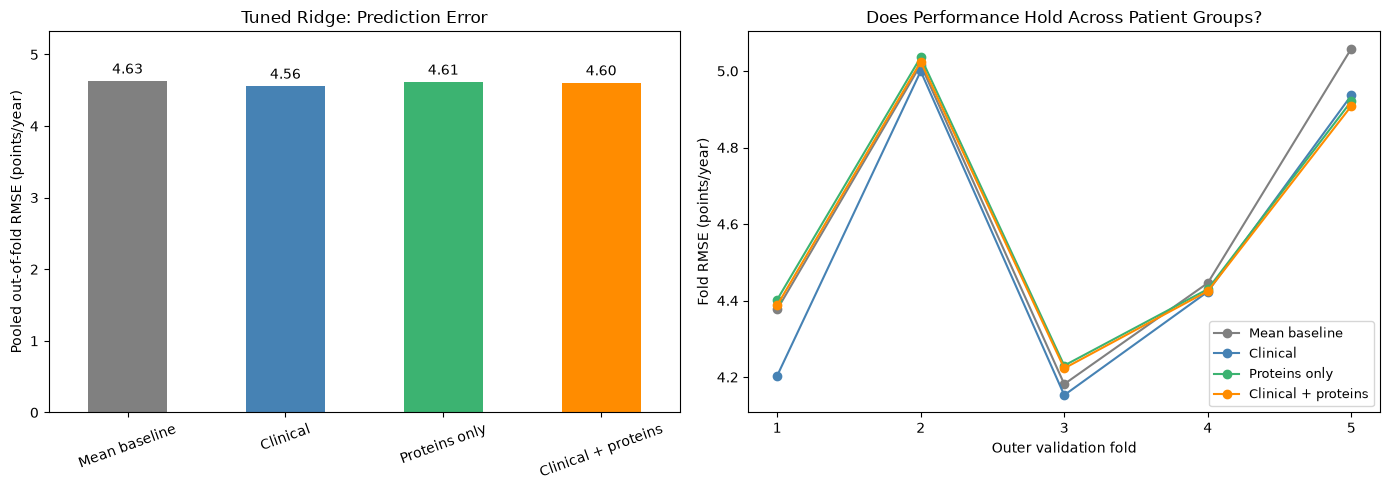

In [67]:
# Left: pooled prediction error. Right: error in each held-out fold.
fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), facecolor="white"
)

performance_cv["RMSE"].plot.bar(
    ax=axes[0],
    color=[colors[name] for name in model_order],
    rot=20
)

axes[0].set_title("Tuned Ridge: Prediction Error")
axes[0].set_xlabel("")
axes[0].set_ylabel("Pooled out-of-fold RMSE (points/year)")
axes[0].bar_label(
    axes[0].containers[0], fmt="%.2f", padding=3
)
axes[0].margins(y=0.15)

for name in model_order:
    axes[1].plot(
        fold_rmse.index,
        fold_rmse[name],
        marker="o",
        color=colors[name],
        label=name
    )

axes[1].set_title("Does Performance Hold Across Patient Groups?")
axes[1].set_xlabel("Outer validation fold")
axes[1].set_ylabel("Fold RMSE (points/year)")
axes[1].set_xticks(fold_rmse.index)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

Clinical-only performed the best overall, with the lowest RMSE of 4.56, but only slightly better than the mean baseline of 4.63.
Adding proteins did not improve overall prediction, with the combined model’s RMSE slightly higher at 4.60.
Performance varied across patient splits, but clinical-only outperformed the combined model in four of five folds.

## 19. Plot individual predictions and errors

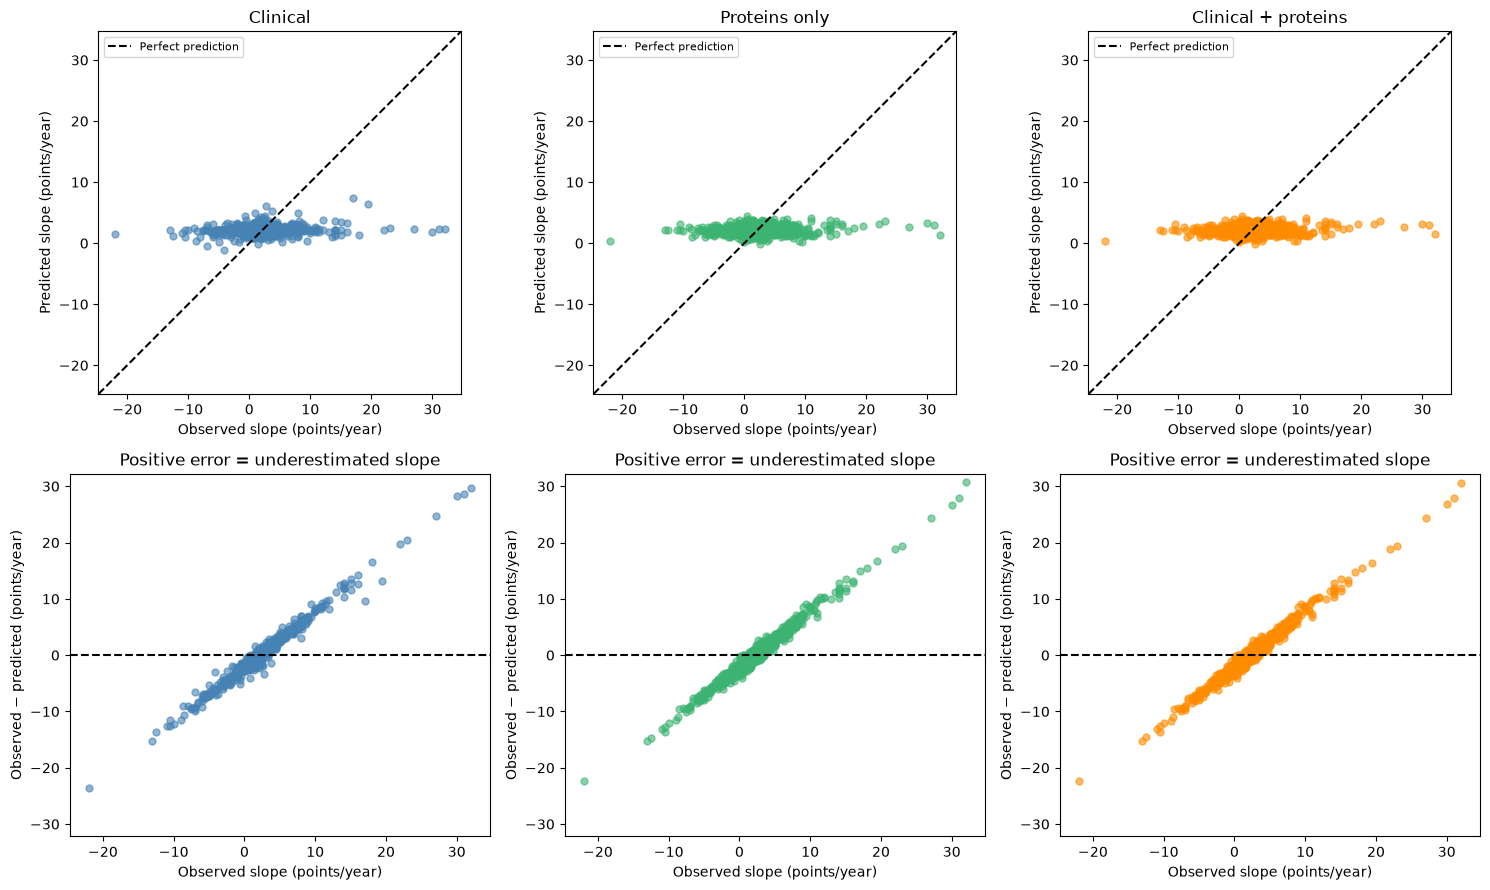

In [68]:
# Top: observed versus predicted. Bottom: observed minus predicted.
ridge_names = [
    "Clinical",
    "Proteins only",
    "Clinical + proteins"
]

all_values = np.concatenate([
    y_cv,
    *[oof_predictions[name] for name in ridge_names]
])

low, high = all_values.min(), all_values.max()
padding = max((high - low) * 0.05, 0.1)
limits = [low - padding, high + padding]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 9), facecolor="white"
)

for j, name in enumerate(ridge_names):
    predicted = oof_predictions[name]

    # Observed versus predicted
    ax = axes[0, j]
    ax.scatter(
        y_cv, predicted,
        color=colors[name], alpha=0.6, s=25
    )
    ax.plot(limits, limits, "k--", label="Perfect prediction")
    ax.set(
        title=name,
        xlabel="Observed slope (points/year)",
        ylabel="Predicted slope (points/year)",
        xlim=limits,
        ylim=limits
    )
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=8)

    # Error versus observed slope
    ax = axes[1, j]
    residual = y_cv - predicted

    ax.scatter(
        y_cv, residual,
        color=colors[name], alpha=0.6, s=25
    )
    ax.axhline(0, color="black", linestyle="--")
    ax.set(
        xlabel="Observed slope (points/year)",
        ylabel="Observed − predicted (points/year)",
        title="Positive error = underestimated slope"
    )

# Match residual scales across models.
residuals = np.concatenate([
    y_cv - oof_predictions[name]
    for name in ridge_names
])
bound = max(np.abs(residuals).max() * 1.05, 0.1)

for ax in axes[1]:
    ax.set_ylim(-bound, bound)

plt.tight_layout()
plt.show()

All three models predict mild worsening for most patients, even when their actual progression rates differ greatly.
The largest errors occur at the extremes: models underestimate rapid worsening and miss improvements in motor scores.
Adding proteins shows little visible improvement over clinical variables alone in predicting individual progression.

## 20. Explore protein coefficient stability

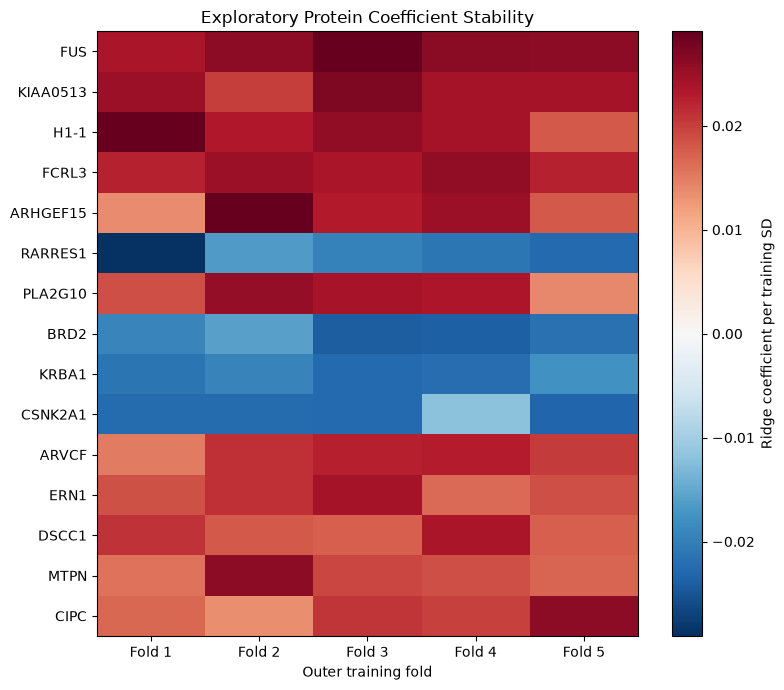

In [69]:
# Compare protein coefficients across overlapping training folds; this is not independent validation.
protein_stability = pd.DataFrame({
    "Mean coefficient": protein_coef_matrix.mean(axis=1),
    "Mean absolute coefficient": protein_coef_matrix.abs().mean(axis=1),
    "Coefficient SD": protein_coef_matrix.std(axis=1),
    "Positive folds": (protein_coef_matrix > 0).sum(axis=1),
    "Negative folds": (protein_coef_matrix < 0).sum(axis=1)
}).sort_values(
    "Mean absolute coefficient",
    ascending=False
)

display(protein_stability.head(15).round(3))

top_proteins = protein_stability.head(15).index
heatmap_data = protein_coef_matrix.loc[top_proteins]

labels = [
    name.replace("harmonized_olink_csf_", "").removesuffix("_NPX")
    for name in top_proteins
]

color_limit = max(
    np.abs(heatmap_data.to_numpy()).max(),
    1e-8
)

fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")

im = ax.imshow(
    heatmap_data.to_numpy(),
    aspect="auto",
    cmap="RdBu_r",
    vmin=-color_limit,
    vmax=color_limit
)

ax.set_xticks(
    range(heatmap_data.shape[1]),
    heatmap_data.columns
)
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Exploratory Protein Coefficient Stability")
ax.set_xlabel("Outer training fold")

fig.colorbar(
    im, ax=ax,
    label="Ridge coefficient per training SD"
)

plt.tight_layout()
plt.show()

FUS, H1-1, and KIAA0513 had consistently higher positive protein coefficients over the five folds, suggesting that higher levels of these proteins are associated with greater increases in UPDRS III score change/year.
On the other hand, BRD2, CSNK2A1 had negative protein coefficients across the five folds, suggesting that higher levels of these proteins are associated with the least increases in UPDRS III score change/year.

## Final Conclusion

After tuning and cross-validation, adding protein data did not meaningfully improve prediction of motor progression. The clinical-only model had the lowest RMSE (4.56), compared with proteins alone (4.61) and clinical plus proteins (4.60), although all models performed close to the mean baseline (4.63). Clinical-only also outperformed the combined model in four of five validation folds.

All three models struggled with extreme progression rates, generally predicting mild worsening. The small number of patients with extreme slopes may have limited the models’ ability to learn these patterns. Some proteins showed consistent coefficient directions across folds, but these remain exploratory associations. Overall, these results suggest limited additional predictive value from proteins in this dataset and modeling approach.